# Teks — Klasifikasi Multilabel (satu teks bisa punya beberapa label)
**Kapan dipakai:** tiap teks boleh punya lebih dari satu label sekaligus, misalnya ulasan
yang membahas harga DAN layanan. Target berupa beberapa kolom 0/1.

**Langkah:** TF-IDF → satu classifier per label (OneVsRest) → F1 macro, Hamming loss.

**Data demo:** CASA (ulasan mobil, 6 label: fuel, machine, others, part, price, service).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score, hamming_loss
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multioutput import ClassifierChain, MultiOutputClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/text/multilabel"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/casa_train.csv"
TEST_CSV = f"{DATA_FOLDER}/casa_test.csv"

TEXT_COL = "text"
TARGETS = ["fuel", "machine", "others", "part", "price", "service"]
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train.isna().sum())
train.head()

train: (810, 8) | test: (90, 2)
id         0
text       0
fuel       0
machine    0
others     0
part       0
price      0
service    0
dtype: int64


,id,text,fuel,machine,others,part,price,service
0,1,Saya memakai Honda Jazz GK5 tahun 2014 ( perta...,0,0,1,0,0,0
1,2,Avanza kenapa jadi boros bensin begini dah ah....,1,0,0,0,0,0
2,3,"saran ku dan pengalaman ku , mending beli mobi...",1,1,0,0,0,0
3,4,Dari segi harga juga pajero lebih mahal 30 jut...,0,0,0,0,1,0
4,5,Kalo menurut gw enak pajero si,0,0,1,0,0,0


## EDA: seberapa sering tiap label muncul

fuel       0.162
machine    0.216
others     0.344
part       0.289
price      0.168
service    0.148
dtype: float64


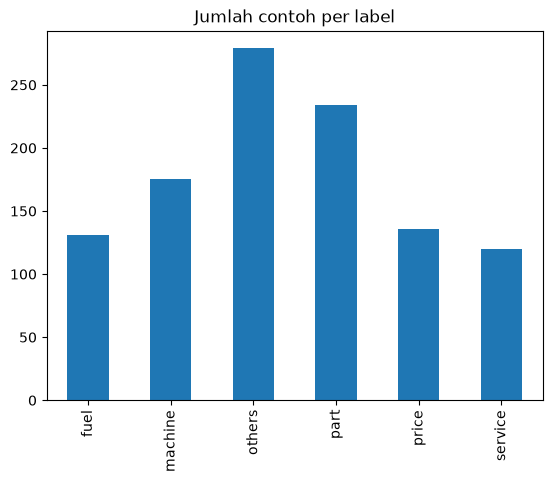

In [4]:
print(train[TARGETS].mean().round(3))
label_counts = train[TARGETS].sum()
label_counts.plot.bar(title="Jumlah contoh per label")
plt.show()

## Split train / validasi

In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    train[TEXT_COL], train[TARGETS], test_size=0.2, random_state=SEED
)

## Model
`OneVsRestClassifier` = satu model terpisah untuk tiap label.
`ClassifierChain` = model label berikutnya ikut melihat tebakan label sebelumnya.
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.

In [6]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
# vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2,
#                              sublinear_tf=True)   # tahan salah ketik

model = OneVsRestClassifier(LogisticRegression(C=5, max_iter=2000))
# model = OneVsRestClassifier(LinearSVC(C=0.5))
# model = OneVsRestClassifier(ComplementNB(alpha=0.3))
# model = MultiOutputClassifier(LogisticRegression(C=5, max_iter=2000))
# model = ClassifierChain(LogisticRegression(C=5, max_iter=2000), random_state=SEED)
# model = OneVsRestClassifier(RidgeClassifier(alpha=1.0))
# model = OneVsRestClassifier(SGDClassifier(loss="modified_huber", random_state=SEED))

pipe = make_pipeline(vectorizer, model)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('onevsrestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](6,)","[0,1,2,3,4,5]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


## Evaluasi di validasi
- F1 macro: rata-rata F1 semua label.
- Hamming loss: persen sel label yang salah (makin kecil makin baik).
- Akurasi subset: persen teks yang SEMUA labelnya benar (paling ketat).

In [7]:
val_predictions = pipe.predict(X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print("Hamming loss:", round(hamming_loss(y_val, val_predictions), 4))
print("Akurasi subset:", round(accuracy_score(y_val, val_predictions), 4))
print(classification_report(y_val, val_predictions, target_names=TARGETS, zero_division=0))

F1 macro: 0.7264
Hamming loss: 0.108
Akurasi subset: 0.5185
              precision    recall  f1-score   support

        fuel       1.00      0.71      0.83        24
     machine       1.00      0.53      0.69        38
      others       0.78      0.44      0.57        63
        part       0.87      0.65      0.74        40
       price       1.00      0.62      0.77        29
     service       1.00      0.62      0.76        21

   micro avg       0.91      0.57      0.70       215
   macro avg       0.94      0.59      0.73       215
weighted avg       0.91      0.57      0.70       215
 samples avg       0.69      0.61      0.63       215



## Latih ulang di semua data + submission
Satu kolom submission per label.

In [8]:
pipe.fit(train[TEXT_COL], train[TARGETS])
predictions = pipe.predict(test[TEXT_COL])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["fuel"] = predictions[:, 0]
submission["machine"] = predictions[:, 1]
submission["others"] = predictions[:, 2]
submission["part"] = predictions[:, 3]
submission["price"] = predictions[:, 4]
submission["service"] = predictions[:, 5]
submission.to_csv("submission.csv", index=False)
submission.head()

,id,fuel,machine,others,part,price,service
0,100001,1,1,0,0,0,0
1,100002,0,1,0,0,0,0
2,100003,1,0,0,0,0,0
3,100004,0,0,1,0,0,0
4,100005,0,0,1,0,1,0
